## Basic Data Quality Check

In [1]:
import pandas as pd
# Load the dataset
df = pd.read_csv(r"E:\DATA SCIENTIST\ML\repository\project\car_price_prediction.csv")

In [2]:
# 1. Dataset shape
print("Dataset Shape:", df.shape)

Dataset Shape: (19237, 18)


In [3]:
# 2. Column names
print("\nColumn Names:")
df.columns


Column Names:


Index(['ID', 'Price', 'Levy', 'Manufacturer', 'Model', 'Prod. year',
       'Category', 'Leather interior', 'Fuel type', 'Engine volume', 'Mileage',
       'Cylinders', 'Gear box type', 'Drive wheels', 'Doors', 'Wheel', 'Color',
       'Airbags'],
      dtype='object')

In [4]:
# 3. Data types
print("\nData Types:")
print(df.dtypes)


Data Types:
ID                    int64
Price                 int64
Levy                 object
Manufacturer         object
Model                object
Prod. year            int64
Category             object
Leather interior     object
Fuel type            object
Engine volume        object
Mileage              object
Cylinders           float64
Gear box type        object
Drive wheels         object
Doors                object
Wheel                object
Color                object
Airbags               int64
dtype: object


In [5]:
# 4. Missing values
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
ID                  0
Price               0
Levy                0
Manufacturer        0
Model               0
Prod. year          0
Category            0
Leather interior    0
Fuel type           0
Engine volume       0
Mileage             0
Cylinders           0
Gear box type       0
Drive wheels        0
Doors               0
Wheel               0
Color               0
Airbags             0
dtype: int64


In [6]:
# 5. Total missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())


Total Missing Values: 0


In [7]:
# 6. Duplicate records
print("\nDuplicate Records:", df.duplicated().sum())


Duplicate Records: 313


In [8]:
# 7. Descriptive statistics
print("\nDescriptive Statistics:")
df.describe()


Descriptive Statistics:


,ID,Price,Prod. year,Cylinders,Airbags
count,1.923700e+04,1.923700e+04,19237.000000,19237.000000,19237.000000
mean,4.557654e+07,1.855593e+04,2010.912824,4.582991,6.582627
std,9.365914e+05,1.905813e+05,5.668673,1.199933,4.320168
min,2.074688e+07,1.000000e+00,1939.000000,1.000000,0.000000
25%,4.569837e+07,5.331000e+03,2009.000000,4.000000,4.000000
50%,4.577231e+07,1.317200e+04,2012.000000,4.000000,6.000000
75%,4.580204e+07,2.207500e+04,2015.000000,4.000000,12.000000
max,4.581665e+07,2.630750e+07,2020.000000,16.000000,16.000000


In [9]:
# 8. First five records
print("\nFirst Five Records:")
df.head()


First Five Records:


,ID,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags
0,45654403,13328,1399,LEXUS,RX 450,2010,Jeep,Yes,Hybrid,3.5,186005 km,6.0,Automatic,4x4,04-May,Left wheel,Silver,12
1,44731507,16621,1018,CHEVROLET,Equinox,2011,Jeep,No,Petrol,3,192000 km,6.0,Tiptronic,4x4,04-May,Left wheel,Black,8
2,45774419,8467,-,HONDA,FIT,2006,Hatchback,No,Petrol,1.3,200000 km,4.0,Variator,Front,04-May,Right-hand drive,Black,2
3,45769185,3607,862,FORD,Escape,2011,Jeep,Yes,Hybrid,2.5,168966 km,4.0,Automatic,4x4,04-May,Left wheel,White,0
4,45809263,11726,446,HONDA,FIT,2014,Hatchback,Yes,Petrol,1.3,91901 km,4.0,Automatic,Front,04-May,Left wheel,Silver,4


## Step 2: Data Cleaning

In [10]:
# 1. Remove duplicate records
df_clean = df.drop_duplicates().copy()

In [11]:
print("Duplicates Removed:", df.shape[0] - df_clean.shape[0])

Duplicates Removed: 313


In [12]:
# 2. Handle missing Levy values
df_clean["Levy"] = df_clean["Levy"].replace("-", pd.NA)
df_clean["Levy"] = pd.to_numeric(
    df_clean["Levy"], errors="coerce"
)

In [13]:
# Fill missing Levy values with the median
levy_median = df_clean["Levy"].median()
df_clean["Levy"] = df_clean["Levy"].fillna(levy_median)

In [14]:
# 3. Clean Mileage values
# Remove the 'km' suffix and convert to numeric
df_clean["Mileage"] = pd.to_numeric(
    df_clean["Mileage"]
    .astype(str)
    .str.replace(" km", "", regex=False)
    .str.replace(",", "", regex=False),
    errors="coerce"
)

In [15]:
# 4. Remove unnecessary leading/trailing spaces
columns_to_clean = [
    "Manufacturer",
    "Model",
    "Category",
    "Fuel type"
]

for col in columns_to_clean:
    df_clean[col] = df_clean[col].astype(str).str.strip()

In [16]:
# 5. Check the cleaned dataset
print("\nCleaned Dataset Shape:", df_clean.shape)


Cleaned Dataset Shape: (18924, 18)


In [17]:
print("\nMissing Values After Cleaning:")
print(df_clean.isnull().sum())


Missing Values After Cleaning:
ID                  0
Price               0
Levy                0
Manufacturer        0
Model               0
Prod. year          0
Category            0
Leather interior    0
Fuel type           0
Engine volume       0
Mileage             0
Cylinders           0
Gear box type       0
Drive wheels        0
Doors               0
Wheel               0
Color               0
Airbags             0
dtype: int64


In [18]:
print("\nTotal Missing Values:",
      df_clean.isnull().sum().sum())


Total Missing Values: 0


In [19]:
print("\nDuplicate Records After Cleaning:",
      df_clean.duplicated().sum())


Duplicate Records After Cleaning: 0


In [20]:
print("\nUpdated Data Types:")
print(df_clean.dtypes)


Updated Data Types:
ID                    int64
Price                 int64
Levy                float64
Manufacturer         object
Model                object
Prod. year            int64
Category             object
Leather interior     object
Fuel type            object
Engine volume        object
Mileage               int64
Cylinders           float64
Gear box type        object
Drive wheels         object
Doors                object
Wheel                object
Color                object
Airbags               int64
dtype: object


In [21]:
# Display cleaned data
print("\nFirst Five Cleaned Records:")
df_clean.head()


First Five Cleaned Records:


,ID,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags
0,45654403,13328,1399.0,LEXUS,RX 450,2010,Jeep,Yes,Hybrid,3.5,186005,6.0,Automatic,4x4,04-May,Left wheel,Silver,12
1,44731507,16621,1018.0,CHEVROLET,Equinox,2011,Jeep,No,Petrol,3,192000,6.0,Tiptronic,4x4,04-May,Left wheel,Black,8
2,45774419,8467,781.0,HONDA,FIT,2006,Hatchback,No,Petrol,1.3,200000,4.0,Variator,Front,04-May,Right-hand drive,Black,2
3,45769185,3607,862.0,FORD,Escape,2011,Jeep,Yes,Hybrid,2.5,168966,4.0,Automatic,4x4,04-May,Left wheel,White,0
4,45809263,11726,446.0,HONDA,FIT,2014,Hatchback,Yes,Petrol,1.3,91901,4.0,Automatic,Front,04-May,Left wheel,Silver,4


## Step 2: Exploratory Data Analysis (EDA)

In [22]:
# Descriptive statistics of numerical columns
print("Descriptive Statistics:")
df_clean.describe()

Descriptive Statistics:


,ID,Price,Levy,Prod. year,Mileage,Cylinders,Airbags
count,1.892400e+04,1.892400e+04,18924.000000,18924.000000,1.892400e+04,18924.000000,18924.000000
mean,4.557538e+07,1.858744e+04,868.498890,2010.914236,1.555373e+06,4.580216,6.568379
std,9.375468e+05,1.921356e+05,391.400489,5.665749,4.880221e+07,1.200223,4.322323
min,2.074688e+07,1.000000e+00,87.000000,1939.000000,0.000000e+00,1.000000,0.000000
25%,4.569501e+07,5.331000e+03,730.000000,2009.000000,7.019575e+04,4.000000,4.000000
50%,4.577191e+07,1.317200e+04,781.000000,2012.000000,1.264000e+05,4.000000,6.000000
75%,4.580174e+07,2.206300e+04,917.000000,2015.000000,1.891198e+05,4.000000,12.000000
max,4.581665e+07,2.630750e+07,11714.000000,2020.000000,2.147484e+09,16.000000,16.000000


In [23]:
# Descriptive statistics of categorical columns
print("\nCategorical Data Statistics:")
df_clean.describe(include="object")


Categorical Data Statistics:


,Manufacturer,Model,Category,Leather interior,Fuel type,Engine volume,Gear box type,Drive wheels,Doors,Wheel,Color
count,18924,18924,18924,18924,18924,18924,18924,18924,18924,18924,18924
unique,65,1590,11,2,7,107,4,3,3,2,16
top,HYUNDAI,Prius,Sedan,Yes,Petrol,2,Automatic,Front,04-May,Left wheel,Black
freq,3729,1069,8600,13731,9944,3856,13282,12695,18032,17471,4944


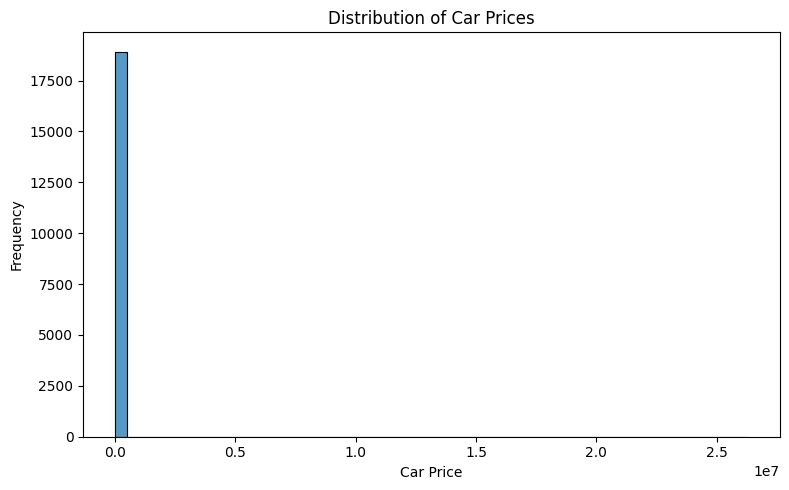

In [24]:
# Histograms
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(data=df_clean, x="Price", bins=50)

plt.title("Distribution of Car Prices")
plt.xlabel("Car Price")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

**Obesrvation :**

    The average car price is higher than the median price, indicating a right-skewed distribution. A few cars have very high prices.

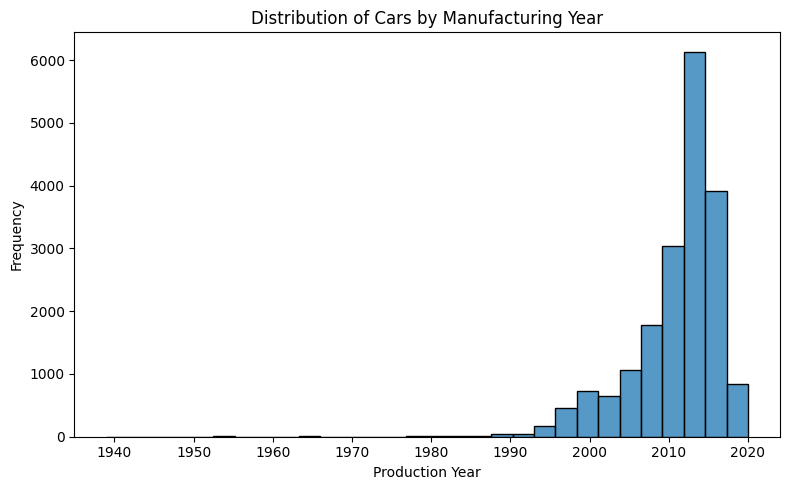

In [25]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df_clean, x="Prod. year", bins=30)

plt.title("Distribution of Cars by Manufacturing Year")
plt.xlabel("Production Year")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

**Observation :**

    Newer cars may have different prices from older cars, but the calculated linear correlation in this dataset is very weak.

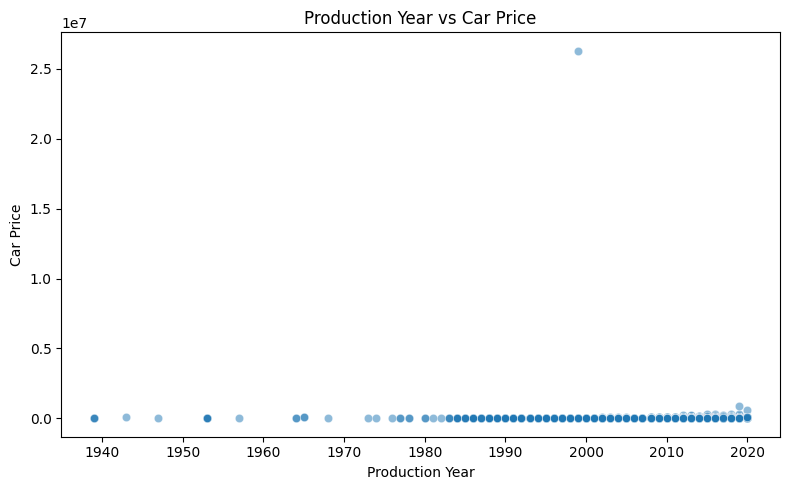

In [26]:
# Scatter Plots
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_clean,
    x="Prod. year",
    y="Price",
    alpha=0.5
)

plt.title("Production Year vs Car Price")
plt.xlabel("Production Year")
plt.ylabel("Car Price")

plt.tight_layout()
plt.show()


**Observation :**

    The linear correlation between production year and price is approximately 0.013, indicating almost no linear relationship across the complete dataset.

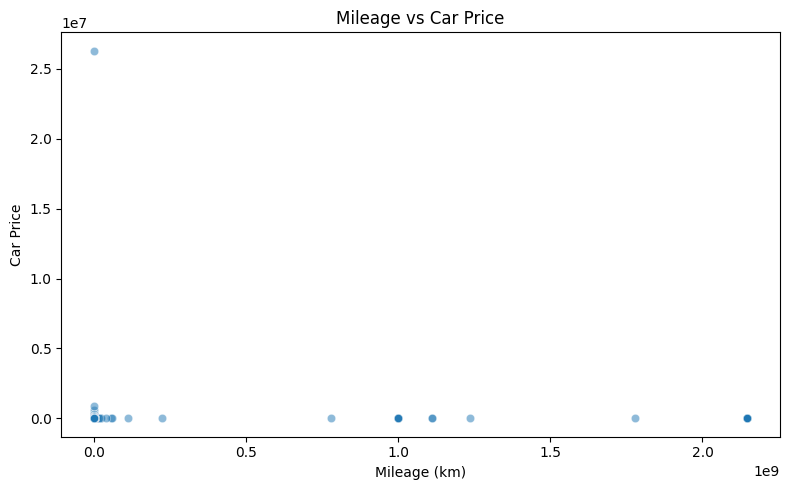

In [27]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_clean,
    x="Mileage",
    y="Price",
    alpha=0.5
)

plt.title("Mileage vs Car Price")
plt.xlabel("Mileage (km)")
plt.ylabel("Car Price")

plt.tight_layout()
plt.show()


**Observation :**

    The linear correlation is approximately −0.002, indicating almost no linear relationship in the current data.

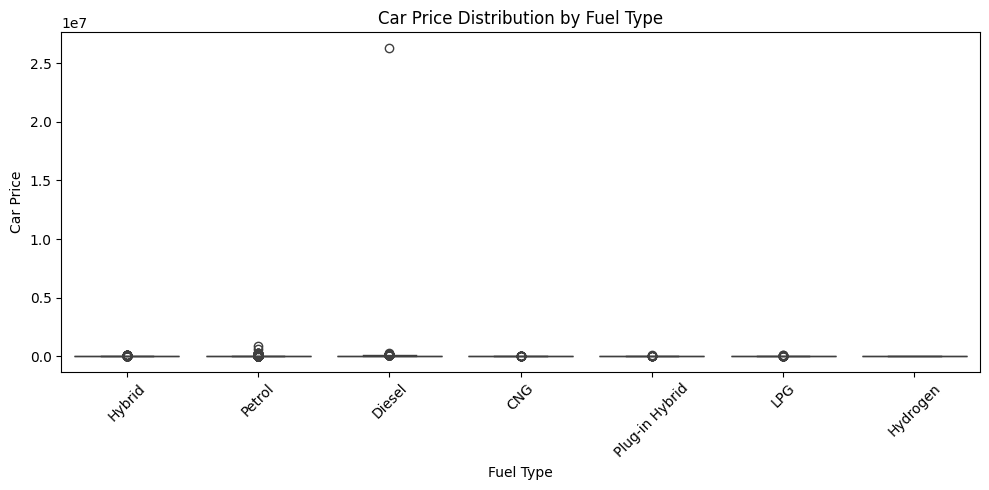

In [28]:
# Boxplot
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_clean,
    x="Fuel type",
    y="Price"
)

plt.title("Car Price Distribution by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Car Price")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**Observation :**

    Median prices vary by fuel type. Diesel cars have a median price of approximately 20,438, while hybrid cars have a median price of approximately 10,036.

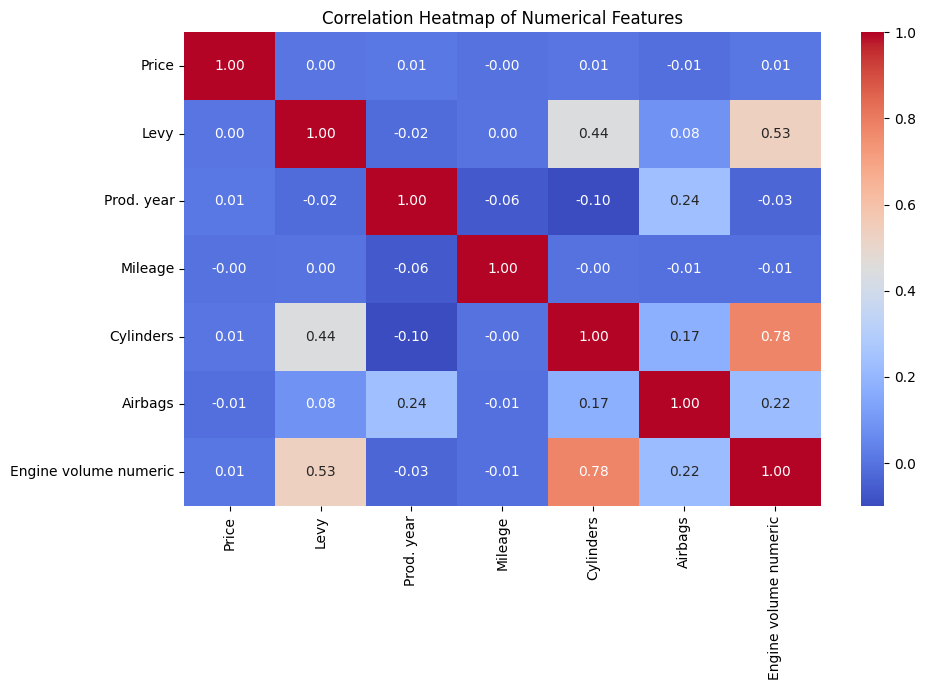

In [29]:
# Correlation Heatmap
# Prepare numerical engine volume for analysis
eda_df = df_clean.copy()

eda_df["Engine volume numeric"] = pd.to_numeric(
    eda_df["Engine volume"]
    .astype(str)
    .str.extract(r"(\d+(?:\.\d+)?)")[0],
    errors="coerce"
)

# Select numerical columns
numeric_cols = [
    "Price",
    "Levy",
    "Prod. year",
    "Mileage",
    "Cylinders",
    "Airbags",
    "Engine volume numeric"
]

correlation_matrix = eda_df[numeric_cols].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Features")

plt.tight_layout()
plt.show()


**Observation :**

    The numerical features show very weak linear correlations with price. This does not rule out nonlinear relationships or relationships involving categorical features.

## Step 3: Model Development

In [30]:
from sklearn.model_selection import train_test_split
# Define independent variables and target variable
X = df_clean.drop(columns=["Price"])
y = df_clean["Price"]

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [31]:
# Display dataset shapes
print("Original Dataset Shape:", df_clean.shape)

print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)

print("y_train Shape:", y_train.shape)
print("y_test Shape:", y_test.shape)


Original Dataset Shape: (18924, 18)
X_train Shape: (15139, 17)
X_test Shape: (3785, 17)
y_train Shape: (15139,)
y_test Shape: (3785,)


In [32]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer

cat = list(X.select_dtypes(include='object').columns) 
con = list(X.select_dtypes(include='number').columns)

num_pipe = make_pipeline(SimpleImputer(strategy='median'),
                         StandardScaler())

cat_pipe = make_pipeline(SimpleImputer(strategy='most_frequent'),
                         OneHotEncoder(handle_unknown='ignore',sparse_output=False))

pre = ColumnTransformer([('cat',cat_pipe,cat),
                         ('con',num_pipe,con)]).set_output(transform='pandas')

pre

,transformers,"[('cat', ...), ('con', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'most_frequent'
,fill_value,None


In [33]:
pre.fit(X_train)

,transformers,"[('cat', ...), ('con', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'most_frequent'
,fill_value,None


In [34]:
xtrain1_pre = pre.transform(X_train)
xtest1_pre = pre.transform(X_test)

In [35]:
xtrain1_pre.head(2)

,cat__Manufacturer_ACURA,cat__Manufacturer_ALFA ROMEO,cat__Manufacturer_ASTON MARTIN,cat__Manufacturer_AUDI,cat__Manufacturer_BENTLEY,cat__Manufacturer_BMW,cat__Manufacturer_BUICK,cat__Manufacturer_CADILLAC,cat__Manufacturer_CHEVROLET,cat__Manufacturer_CHRYSLER,...,cat__Color_Silver,cat__Color_Sky blue,cat__Color_White,cat__Color_Yellow,con__ID,con__Levy,con__Prod. year,con__Mileage,con__Cylinders,con__Airbags
8727,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.165858,-0.607162,0.549520,-0.029068,-0.482483,-0.594303
4808,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.194181,2.499757,-0.163808,-0.026706,2.842572,-1.520746


## Model Building

In [44]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Identify numerical and categorical features
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Preprocessing for numerical features
numeric_transformer = SimpleImputer(strategy="median")

# Preprocessing for categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Build the Linear Regression model
lr_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])



In [46]:

from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Create the Linear Regression pipeline
lr_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Define hyperparameters
param_grid = {
    "regressor__fit_intercept": [True, False]
}

# Perform hyperparameter tuning
grid_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

# Train and tune the model
grid_search.fit(X_train, y_train)

# Display best parameters and score
print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation R2 Score:", grid_search.best_score_)

# Store the best model
best_model = grid_search.best_estimator_


Best Parameters: {'regressor__fit_intercept': True}
Best Cross-Validation R2 Score: -0.008918369975157648


In [47]:

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)
import numpy as np

# Use the best model selected during hyperparameter tuning
final_model = grid_search.best_estimator_

# Predict car prices on unseen test data
y_pred = final_model.predict(X_test)

# Calculate evaluation metrics
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

# Display results
print("Final Model Evaluation Results")
print("-" * 35)
print(f"R2 Score : {r2:.4f}")
print(f"MAE      : {mae:.2f}")
print(f"MSE      : {mse:.2f}")
print(f"RMSE     : {rmse:.2f}")


Final Model Evaluation Results
-----------------------------------
R2 Score : -0.0083
MAE      : 12780.05
MSE      : 349104578.26
RMSE     : 18684.34
